# A4: all-or-none lac induction with our own circuit (Vilar, Guet & Leibler 2003)

**Question.** Does our Gillespie simulation of the A3 v3 circuit give *all-or-none* induction (two separate groups of cells,
each cell switching suddenly at its own time), and not just one noisy group?

**Vilar et al. 2003 (J Cell Biol 161:471), Fig. 3:** (a) at a sub-optimal inducer dose single cells switch abruptly at
random times while the average of 2,000 cells rises smoothly, and a population curve with slower-growing induced cells
lies below it; (b) at a maintenance dose neither induced nor uninduced cells switch; (c) at a high dose every cell switches.

**Here:** our `circuit_model.yaml` (A3 v3), not Vilar's parameters. Doses are scaled to our memory zone (4.1–30 µM TMG).
Simulations: `src/a4_vilar.py` (cached in `outputs/a4/`); this notebook only reads and plots them.
To rerun everything (~20 min): uncomment the `simulate()` line.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import a4_vilar as V
# V.simulate()        # uncomment to rerun all simulations
R = json.loads((V.OUT / "vilar_results.json").read_text())
plt = V._style()
%matplotlib inline

## 1. Memory survives noise: SSA hysteresis (1,000 cells per point, both histories)

,value
switch_on_T50_uM,37.255331
switch_on_T95_uM,None
switch_off_T50_uM,3.411961
switch_off_T95_uM,2.15091
analytic_switch_on_uM,30.0
analytic_switch_off_uM,4.104452
ode_20h_switch_on_uM,36.4
ode_20h_switch_off_uM,2.94
ozbudak_paper_uM,"[3, 30]"
n_cells_per_point,1000


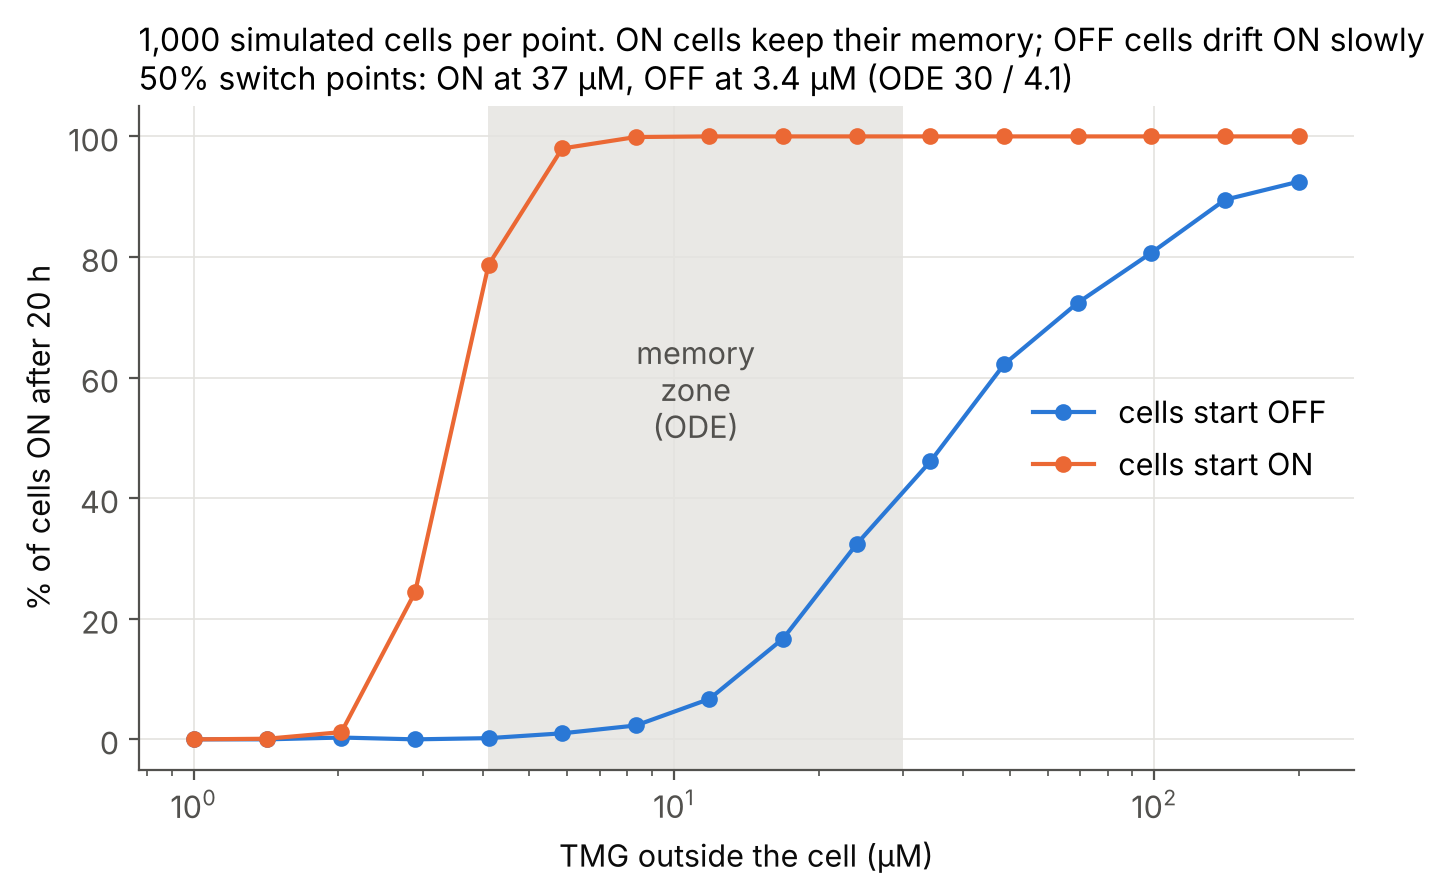

In [2]:
V.fig_hysteresis(plt, save=False)
pd.DataFrame([R["ssa_hysteresis"]]).T.rename(columns={0: "value"})

## 2. Vilar Fig. 3: cells switch suddenly, at different times (cellular + population levels)

,TMG_uM,history,n_cells,fraction_switched_30h,switch_time_median_min,final_cell_avg_Y,final_population_avg_Y
vilar3a_sub,37.3,uninduced,2000,0.675,735.0,936.9425,557.040226
vilar3c_high,500.0,uninduced,2000,0.994,90.0,1492.4495,1438.804807
vilar3b_maint_from_OFF,11.0,uninduced,1000,0.174,885.0,88.74,39.310065
vilar3b_maint_from_ON,11.0,induced,1000,0.0,None,1367.287,1367.287


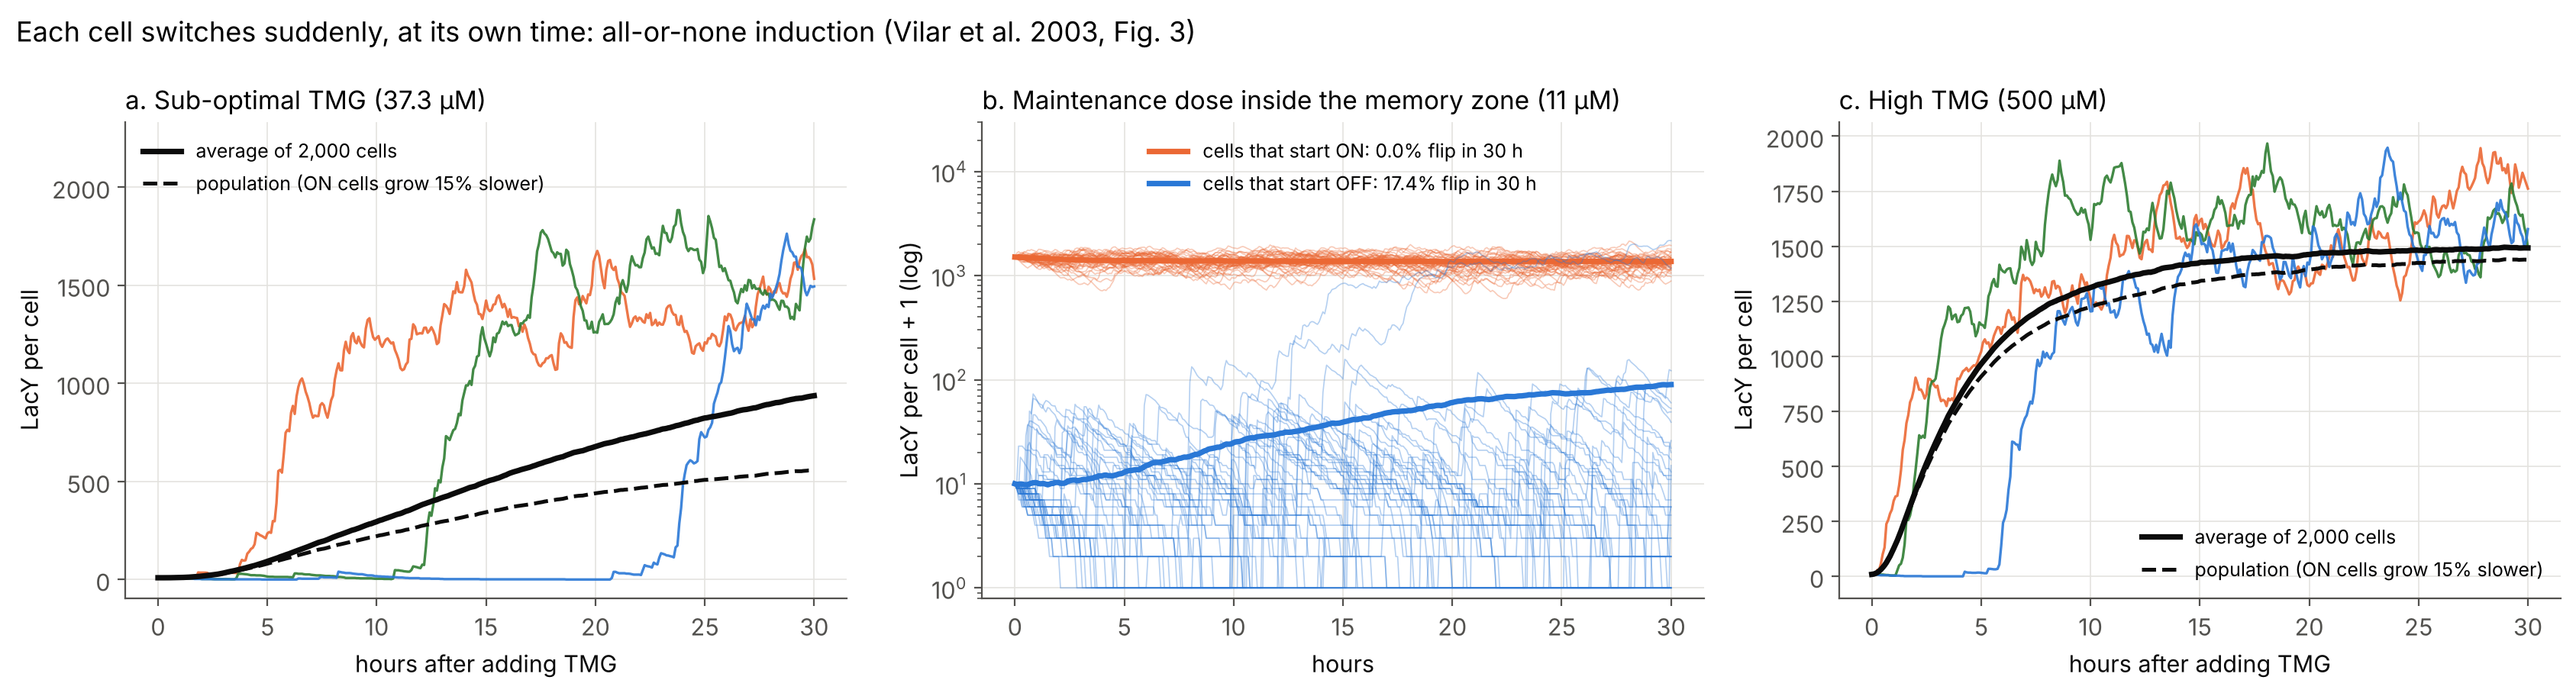

In [3]:
V.fig_vilar3(plt, save=False)
pd.DataFrame({k: {kk: v[kk] for kk in ["TMG_uM", "history", "n_cells", "fraction_switched_30h", "switch_time_median_min",
                                        "final_cell_avg_Y", "final_population_avg_Y"]} for k, v in R["vilar"].items()}).T

In [4]:
a = R["vilar"]["vilar3a_sub"]
print(f"one cell goes from 10% to 90% ON in {a['single_cell_rise_10_90_median_min']:.0f} min (median);")
print(f"the 2,000-cell average takes {a['population_rise_10_90_min']:.0f} min: the average is smooth only because cells switch at different times.")

one cell goes from 10% to 90% ON in 300 min (median);
the 2,000-cell average takes 1256 min: the average is smooth only because cells switch at different times.


## 3. Bimodal, not just noisy: wild type vs a graded (ρ = 5) strain with the same average

,hours,wild type dip p,wild type Sarle BC,wild type % ON,rho=5 dip p,rho=5 Sarle BC
0,0.0,0.834,0.557,0.00,0.770,0.557
1,4.0,0.905,0.673,9.60,0.984,0.379
2,8.0,0.000,0.749,21.45,0.982,0.458
3,12.0,0.000,0.753,32.25,0.994,0.478
4,20.0,0.000,0.812,51.35,0.966,0.497
5,30.0,0.000,0.889,67.00,0.987,0.472


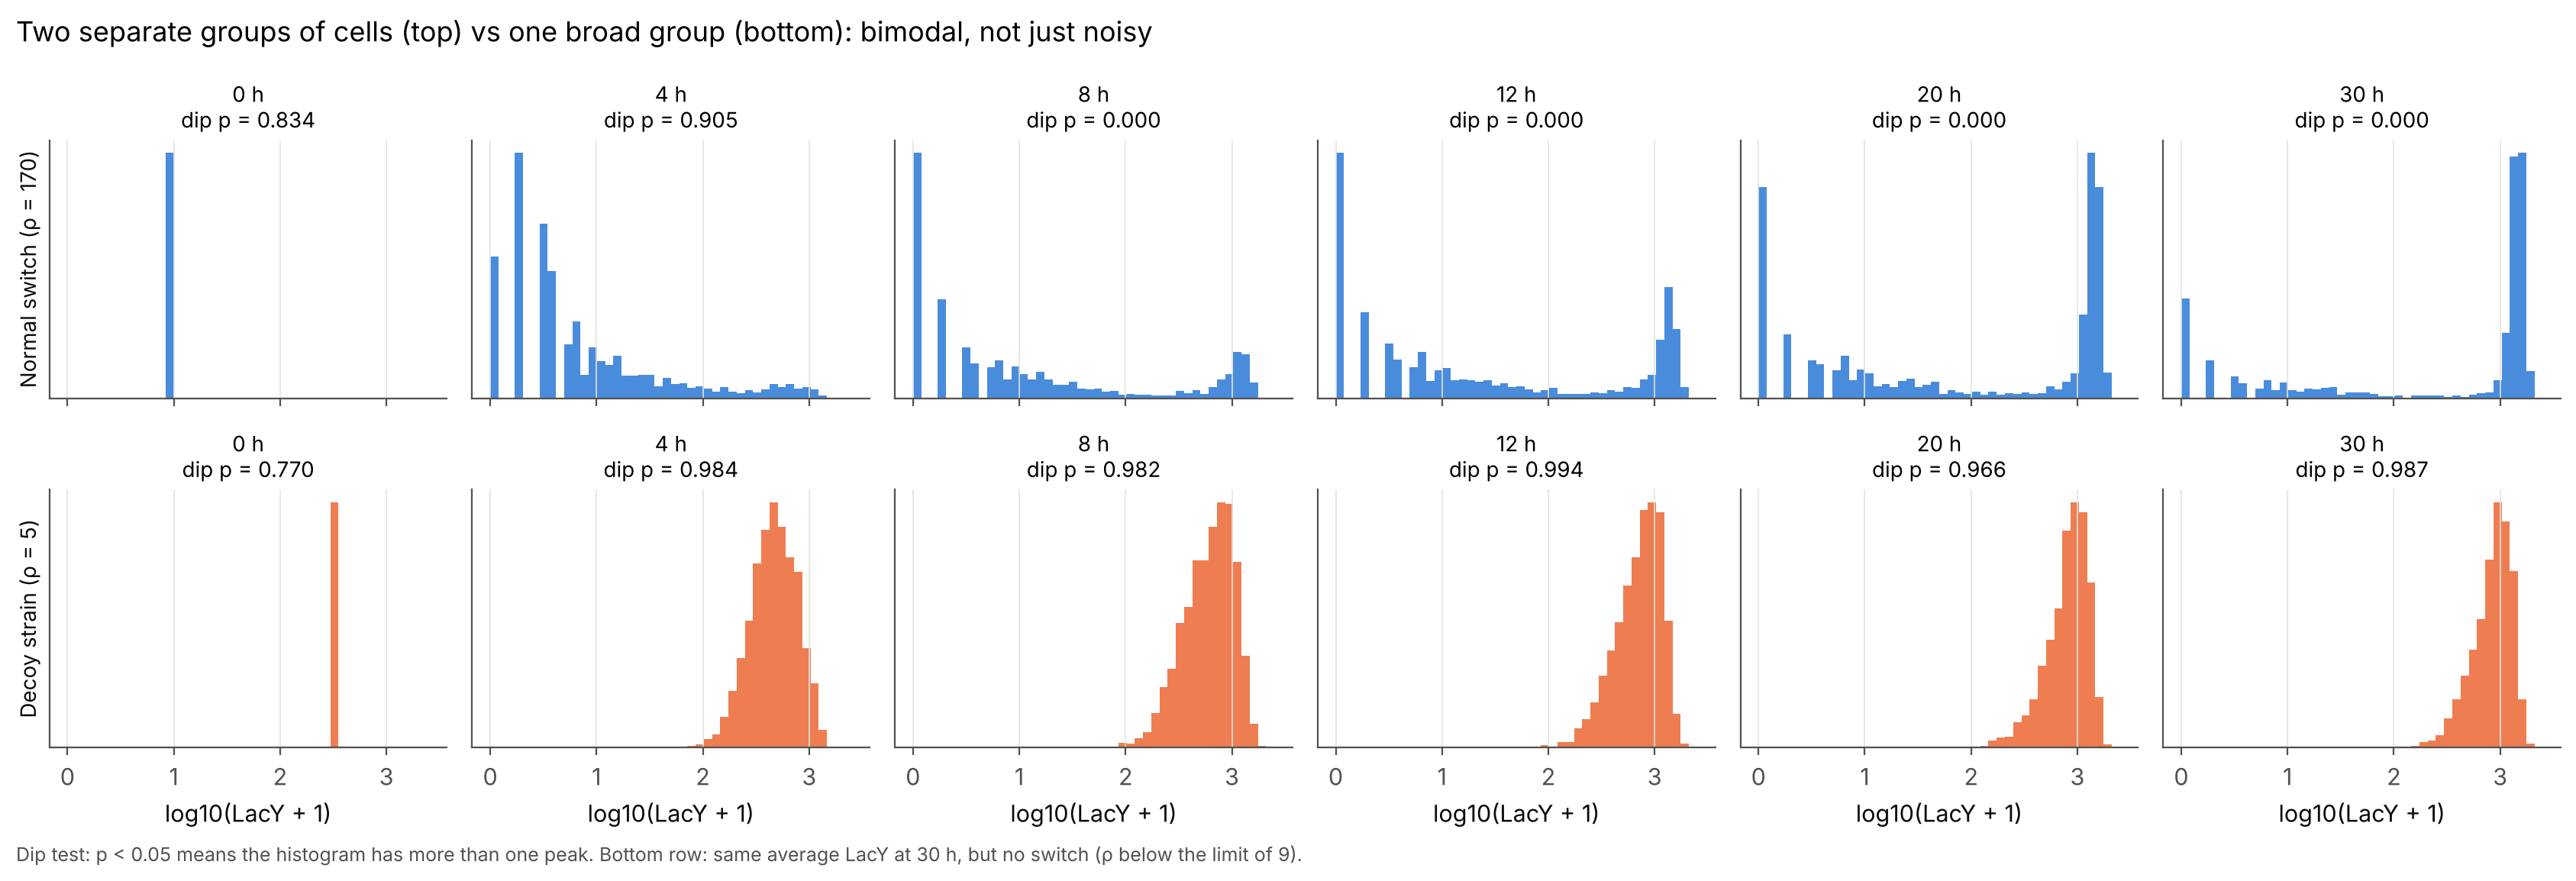

In [5]:
V.fig_bimodality(plt, save=False)
rows = []
for t, b in R["bimodality_wt"].items():
    rows.append({"hours": int(t) / 60, "wild type dip p": b["dip_p"], "wild type Sarle BC": b["sarle_bc"], "wild type % ON": 100 * b["fraction_ON"],
                 "rho=5 dip p": R["rho5_control"]["bimodality_rho5"][t]["dip_p"], "rho=5 Sarle BC": R["rho5_control"]["bimodality_rho5"][t]["sarle_bc"]})
pd.DataFrame(rows).round(3)

## 4. Molecular level: one cell switching (exact simulation, every reaction simulated)

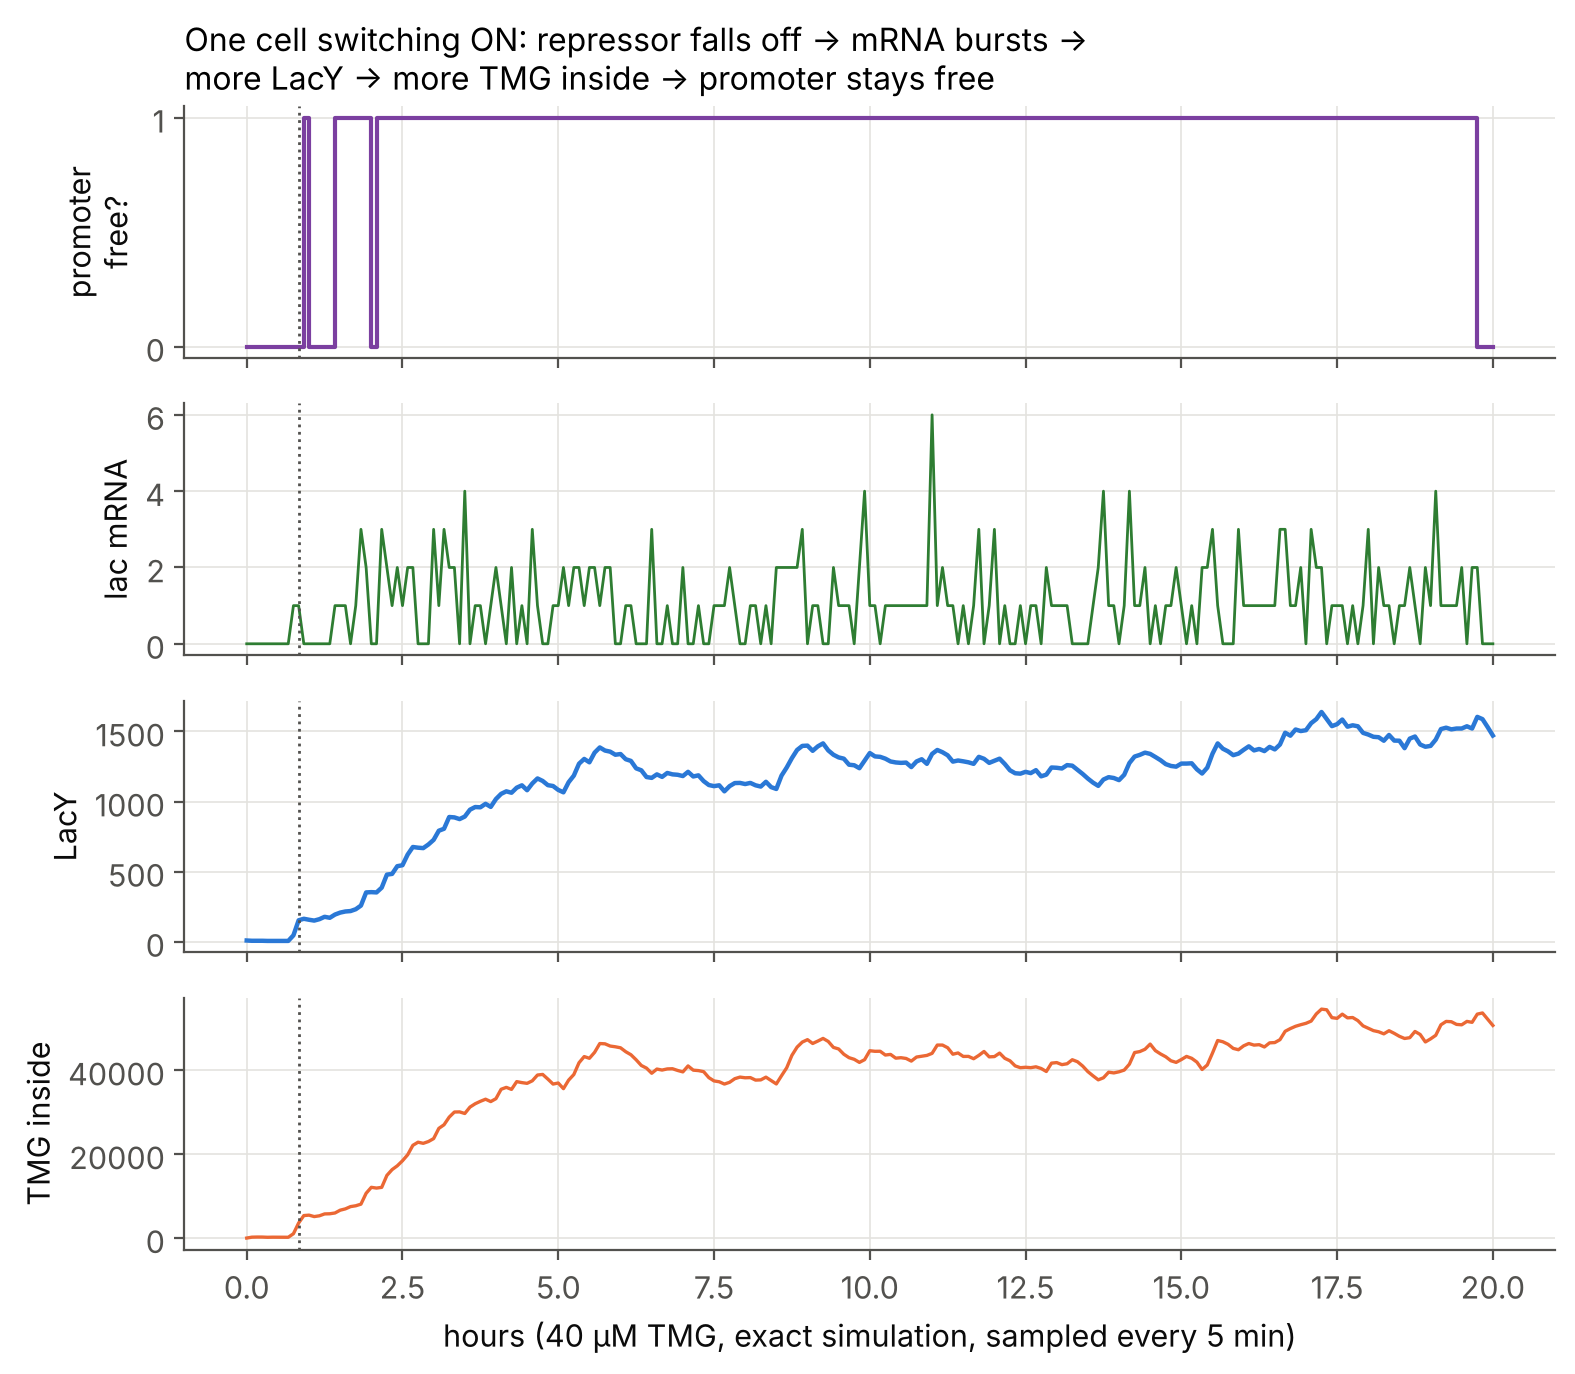

In [6]:
V.fig_molecular(plt, save=False);

## 5. Checks: fast mode vs exact SSA, and the noise knob k_unrep

In [7]:
fe = json.loads((V.OUT / "fast_vs_exact.json").read_text())
pd.DataFrame({k: {"exact % ON": 100 * v["exact"]["fraction_ON_20h"], "fast % ON": 100 * v["fast"]["fraction_ON_20h"],
                  "difference (pp)": 100 * v["switched_fraction_diff"], "± 1 SE (pp)": 100 * v["switched_fraction_diff_se"],
                  "switch-time KS p": v.get("switch_time_KS_p"), "exact ON-cell mean LacY": v["exact"]["mean_Y_ON_cells"],
                  "fast ON-cell mean LacY": v["fast"]["mean_Y_ON_cells"]} for k, v in fe.items() if k != "n_cells"}).T.round(3)

,exact % ON,fast % ON,difference (pp),± 1 SE (pp),switch-time KS p,exact ON-cell mean LacY,fast ON-cell mean LacY
T40_from_OFF,50.75,54.50,-3.25,3.526,0.874,1316.236,1342.413
T15_from_OFF,10.75,12.75,-4.50,2.620,0.557,965.721,1041.078
T15_from_ON,100.00,100.00,0.00,0.000,NaN,1415.040,1400.420


In [8]:
pd.DataFrame(R["k_unrep_sensitivity"]).pivot_table(index=["TMG_uM", "history"], columns="k_unrep", values="fraction_ON_20h").round(3)

k_unrep            0.02   0.10   0.50
TMG_uM history                       
11.0   induced    0.988  1.000  1.000
       uninduced  0.076  0.069  0.065
37.3   uninduced  0.453  0.508  0.541

## 6. Conclusion

See `outputs/a4/a4_report.md` for the numbers in words.